In [12]:
import numpy as np
from matplotlib import pyplot as plt

train_size = 50_000
hidden_size = 64
output_size = 10
learning_rate = 0.05
batch_size = 128
epochs = 10


In [13]:
images = np.fromfile(
    "train-images.idx3-ubyte", dtype=np.uint8, offset=16
).reshape(-1, 784)
labels = np.fromfile(
    "train-labels.idx1-ubyte", dtype=np.uint8, offset=8
)

X = images.astype(np.float32) / 255.0
y = labels.copy()

rng = np.random.default_rng(42)
indices = rng.permutation(len(X))
train_indices = indices[:train_size]
val_indices = indices[train_size:]
X_train, y_train = X[train_indices], y[train_indices]
X_val, y_val = X[val_indices], y[val_indices]


In [14]:
input_size = X_train.shape[1]
network_rng = np.random.default_rng(123)

W1 = network_rng.normal(
    loc=0.0,
    scale=np.sqrt(2.0 / input_size),
    size=(input_size, hidden_size),
).astype(np.float32)
b1 = np.zeros(hidden_size, dtype=np.float32)

W2 = network_rng.normal(
    loc=0.0,
    scale=np.sqrt(1.0 / hidden_size),
    size=(hidden_size, output_size),
).astype(np.float32)
b2 = np.zeros(output_size, dtype=np.float32)


In [15]:
def forward_batch(X_batch):
    Z1 = X_batch @ W1 + b1
    H1 = np.maximum(0, Z1)
    scores = H1 @ W2 + b2

    # Each row represents one image.
    shifted = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(shifted)
    probabilities = exp_scores / exp_scores.sum(
        axis=1, keepdims=True
    )

    return Z1, H1, shifted, probabilities


def batch_loss(shifted, labels):
    rows = np.arange(len(labels))

    losses = (
        np.log(np.exp(shifted).sum(axis=1))
        - shifted[rows, labels]
    )

    return losses.mean()


def evaluate(X_data, y_data, batch_size=512):
    total_loss = 0.0
    total_correct = 0

    for start in range(0, len(X_data), batch_size):
        X_batch = X_data[start:start + batch_size]
        y_batch = y_data[start:start + batch_size]

        _, _, shifted, probabilities = forward_batch(X_batch)

        total_loss += batch_loss(shifted, y_batch) * len(y_batch)
        predictions = probabilities.argmax(axis=1)
        total_correct += np.count_nonzero(predictions == y_batch)

    return (
        total_loss / len(X_data),
        total_correct / len(X_data)
    )


In [16]:
training_rng = np.random.default_rng(456)
history = []

initial_loss, initial_accuracy = evaluate(X_val, y_val)

print(
    f"Before training - validation loss: {initial_loss:.4f}, "
    f"accuracy: {initial_accuracy:.2%}"
)

# Keep the parameters with the lowest validation loss.
best_val_loss = initial_loss

best_parameters = (
    W1.copy(),
    b1.copy(),
    W2.copy(),
    b2.copy()
)

for epoch in range(epochs):
    indices = training_rng.permutation(len(X_train))

    for start in range(0, len(X_train), batch_size):
        batch_indices = indices[start:start + batch_size]

        X_batch = X_train[batch_indices]
        y_batch = y_train[batch_indices]
        actual_batch_size = len(y_batch)

        # Forward pass
        Z1, H1, shifted, probabilities = forward_batch(X_batch)

        # Gradient of the MEAN loss with respect to scores
        d_scores = probabilities.copy()
        rows = np.arange(actual_batch_size)
        d_scores[rows, y_batch] -= 1
        d_scores /= actual_batch_size

        # Output-layer gradients
        d_W2 = H1.T @ d_scores
        d_b2 = d_scores.sum(axis=0)

        # Backpropagate through the hidden layer.
        # Calculate this BEFORE changing W2.
        d_H1 = d_scores @ W2.T
        d_Z1 = d_H1 * (Z1 > 0)

        # Input-to-hidden gradients
        d_W1 = X_batch.T @ d_Z1
        d_b1 = d_Z1.sum(axis=0)

        # Gradient descent: update all parameters
        W1 -= learning_rate * d_W1
        b1 -= learning_rate * d_b1
        W2 -= learning_rate * d_W2
        b2 -= learning_rate * d_b2

    # Measure performance using the parameters at epoch end.
    train_loss, train_accuracy = evaluate(X_train, y_train)
    val_loss, val_accuracy = evaluate(X_val, y_val)

    history.append(
        (train_loss, val_loss, train_accuracy, val_accuracy)
    )

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_accuracy:.2%} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val accuracy: {val_accuracy:.2%}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_parameters = (
            W1.copy(),
            b1.copy(),
            W2.copy(),
            b2.copy()
        )

# Restore the best validation-loss parameters.
W1, b1, W2, b2 = best_parameters

final_loss, final_accuracy = evaluate(X_val, y_val)

print(
    f"\nSelected model - validation loss: {final_loss:.4f}, "
    f"accuracy: {final_accuracy:.2%}"
)


Before training - validation loss: 2.3867, accuracy: 10.12%
Epoch 1/10 | Train loss: 0.3990 | Train accuracy: 89.15% | Val loss: 0.4029 | Val accuracy: 89.09%
Epoch 2/10 | Train loss: 0.3271 | Train accuracy: 90.77% | Val loss: 0.3330 | Val accuracy: 90.56%
Epoch 3/10 | Train loss: 0.2906 | Train accuracy: 91.79% | Val loss: 0.2970 | Val accuracy: 91.69%
Epoch 4/10 | Train loss: 0.2706 | Train accuracy: 92.47% | Val loss: 0.2803 | Val accuracy: 92.01%
Epoch 5/10 | Train loss: 0.2504 | Train accuracy: 93.04% | Val loss: 0.2605 | Val accuracy: 92.52%
Epoch 6/10 | Train loss: 0.2337 | Train accuracy: 93.49% | Val loss: 0.2463 | Val accuracy: 92.93%
Epoch 7/10 | Train loss: 0.2219 | Train accuracy: 93.84% | Val loss: 0.2366 | Val accuracy: 93.21%
Epoch 8/10 | Train loss: 0.2058 | Train accuracy: 94.26% | Val loss: 0.2219 | Val accuracy: 93.66%
Epoch 9/10 | Train loss: 0.1937 | Train accuracy: 94.67% | Val loss: 0.2110 | Val accuracy: 94.17%
Epoch 10/10 | Train loss: 0.1827 | Train accuracy

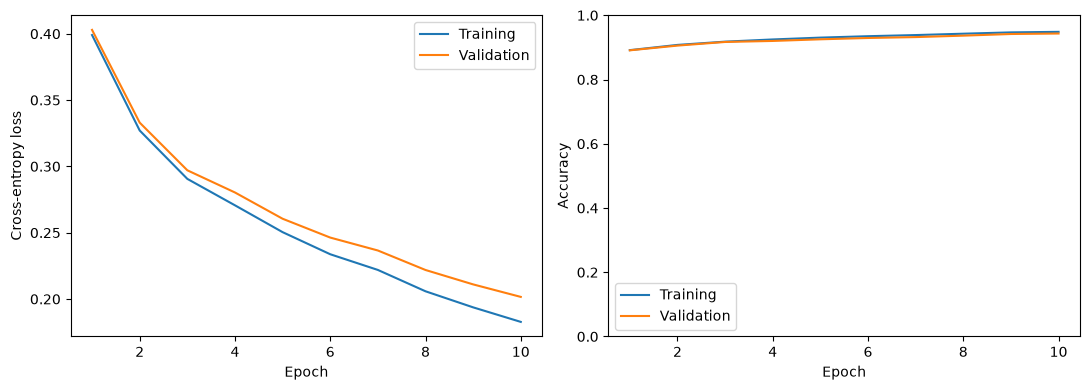

In [17]:
history_array = np.array(history)
epoch_numbers = np.arange(1, epochs + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(epoch_numbers, history_array[:, 0], label="Training")
axes[0].plot(epoch_numbers, history_array[:, 1], label="Validation")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

axes[1].plot(epoch_numbers, history_array[:, 2], label="Training")
axes[1].plot(epoch_numbers, history_array[:, 3], label="Validation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.tight_layout()
plt.show()


In [18]:
np.savez(
    "mnist_model.npz",
    W1=W1,
    b1=b1,
    W2=W2,
    b2=b2
)

print("Saved model to mnist_model.npz")


Saved model to mnist_model.npz


In [19]:
def show_prediction(index):
    image = X_val[index]
    label = int(y_val[index])

    # Keep a batch dimension, even for one image.
    _, _, _, probabilities = forward_batch(image.reshape(1, -1))

    probabilities = probabilities[0]
    prediction = int(probabilities.argmax())

    plt.imshow(
        image.reshape(28, 28),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.title(
        f"Predicted: {prediction} | Correct: {label}\n"
        f"Predicted digit probability: "
        f"{probabilities[prediction]:.1%}"
    )

    plt.axis("off")
    plt.show()

    return prediction, probabilities


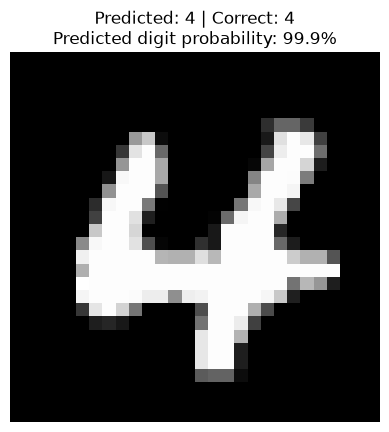

In [20]:
prediction_index = 25
prediction, probabilities = show_prediction(prediction_index)


In [ ]:
validation_loss, validation_accuracy = evaluate(X_val, y_val)

print(f"Model accuracy: {validation_accuracy:.2%}")
print(f"Evaluated on {len(y_val):,} images")


Model accuracy (validation set): 94.32%
Evaluated on 10,000 images
